# Salon Experiment & Causal Analysis

**Bloom & Blade Salon & Spa** is a fictional chain of 22 salons in Coimbatore. Last quarter it launched
**Glow Combos** (a bundled service menu) in its North-zone outlets and announced that revenue per visit
jumped. Nobody checked whether that was real or just the season. It now also wants to try
**Smart Reminders** (WhatsApp reminders with a one-tap reschedule button) to cut no-shows.

This notebook does three things:

| Part | Question | Method |
|---|---|---|
| A | How should we test Smart Reminders? | Hypothesis, metrics, guardrails, power analysis, A/A check |
| B | Did Smart Reminders work? | Sample ratio mismatch, balance, t-test / delta method / bootstrap, segments, CUPED |
| C | Did Glow Combos really work? | Difference-in-differences vs. a comparable control zone, parallel-trend tests, placebos |

Every estimate comes with a 95% confidence interval, and every number quoted in the report is saved to
`reports/results.json` at the end of this notebook.

> **Data note.** All data is synthetic, produced by `src/generate_data.py` (seeded, so it is reproducible).
> It deliberately contains the problems named in the brief: no-shows logged as cancellations, service names
> that differ by outlet, and walk-ins recorded without client IDs.

In [1]:
import sys, json, math, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import cleaning, power_analysis as pa, ab_testing as ab, variance_reduction as vr, did, viz

viz.setup()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
TABLES = ROOT / "reports" / "tables"; TABLES.mkdir(parents=True, exist_ok=True)

if not (ROOT / "data" / "raw" / "appointments.csv.gz").exists():   # first run on a fresh clone
    import subprocess
    subprocess.run([sys.executable, str(ROOT / "src" / "generate_data.py")], check=True)

R = {}                                         # every number used in the report lives here
def f(x):                                      # json-safe floats
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else float(x)
def fmt_ci(d, scale=100, unit="pp", digits=2):
    return f"{d['diff']*scale:+.{digits}f} {unit} (95% CI {d['ci_low']*scale:+.{digits}f} to {d['ci_high']*scale:+.{digits}f})"

## 1. The data and how it was cleaned

Seven raw files, as a chain's tills would export them:

| File | One row per |
|---|---|
| `appointments.csv.gz` | booking or walk-in (outlet, client, stylist, channel, times, status, remarks) |
| `service_lines.csv.gz` | service on an appointment (outlet-specific service name, price, discount, amount) |
| `product_sales.csv.gz` | retail product sale |
| `clients.csv`, `stylists.csv`, `outlets.csv` | client / stylist / outlet |
| `experiment_smart_reminders.csv` | client enrolled in the Smart Reminders A/B test (assignment + outcomes) |

In [2]:
raw = cleaning.load_raw()
sizes = pd.DataFrame({k: [len(v), v.shape[1]] for k, v in raw.items()}, index=["rows", "columns"]).T
display(sizes)
display(raw["appointments"].sample(6, random_state=4))
R["data"] = {"raw_rows": {k: int(len(v)) for k, v in raw.items()}}

,rows,columns
outlets,22,9
stylists,286,6
clients,72259,7
appointments,304810,10
service_lines,458557,6
product_sales,39061,9
experiment,6435,16


,appointment_id,outlet_id,client_id,stylist_id,booking_channel,booked_at,scheduled_start,status,cancelled_at,remarks
175946,APT0175084,BB12,C033294,ST286,App,2026-02-06 15:18:00,2026-02-13 17:30:00,Completed,NaN,NaN
123217,APT0122590,BB22,NaN,ST639,Walk-in,2025-10-24 16:47:00,2025-10-24 16:57:00,Completed,NaN,NaN
244246,APT0243035,BB05,NaN,ST119,Walk-in,2026-07-12 13:17:00,2026-07-12 13:27:00,Completed,NaN,NaN
153660,APT0152894,BB08,NaN,ST183,Walk-in,2025-12-30 13:43:00,2025-12-30 13:47:00,Completed,NaN,NaN
133828,APT0133150,BB02,NaN,ST054,Walk-in,2025-11-16 10:57:00,2025-11-16 11:07:00,Completed,NaN,NaN
300956,APT0299459,BB01,C003595,ST024,WhatsApp,2026-11-07 11:12:00,2026-11-10 18:00:00,Completed,NaN,NaN


The brief warned about three problems; profiling found eight. The rule throughout: **fix and log, never drop
silently**. The cleaning code is in `src/cleaning.py`; the log below is produced by it.

In [3]:
res = cleaning.run_cleaning()
A, V, C = res["appointments"], res["visits"], res["clients"]
qlog = res["quality_log"]
display(qlog.style.format({"share_of_table": "{:.1%}", "rows_affected": "{:,}"}).hide(axis="index"))
qlog.to_csv(TABLES / "data_quality_log.csv", index=False)
R["data"].update({"appointments_clean": int(len(A)), "visits": int(len(V)),
                  "duplicates_dropped": int(qlog.loc[qlog.issue.str.startswith("Exact duplicate"), "rows_affected"].iloc[0]),
                  "outlets": int(A.outlet_id.nunique()),
                  "date_min": str(A.date.min().date()), "date_max": str(A.date.max().date())})

table,issue,rows_affected,share_of_table,fix
clients,Gender coded 6 different ways (F/Female/female/M/Male/male) or blank,"11,369",15.7%,Mapped to F / M; blanks -> 'Unknown'
clients,Age band blank or written '55 +',"3,823",5.3%,Standardised to 18-24 ... 55+; blanks -> 'Unknown'
appointments,Exact duplicate rows from till sync,"1,516",0.5%,Dropped (kept first copy)
appointments,"Two outlets export dates as dd-mm-yyyy, the rest as ISO","36,143",11.9%,Parsed each format explicitly (no day/month guessing)
appointments,"Booking channel spelt 9 ways (e.g. 'walk in', 'WALKIN', 'Mobile App')","41,090",13.6%,Mapped to Walk-in / Phone / WhatsApp / App
appointments,Walk-ins recorded without a client ID,"111,620",36.8%,Kept for outlet-level revenue and visits; excluded from client-level retention and from the A/B test
appointments,Stylist ID in lower case or with stray spaces,"6,549",2.2%,Trimmed and upper-cased
appointments,Stylist ID missing,"4,729",1.6%,Left blank; only used for stylist-level breakdowns
appointments,Status spelt 7 ways (Completed/completed/Done/Cancelled/CANCELLED/Canceled/No Show),"29,576",9.8%,Mapped to completed / cancelled / no_show
appointments,No-shows (and <2h late cancellations) logged as 'Cancelled',"18,567",6.1%,Re-classified with cancellation timestamp + remarks (see outcome_rule)


### 1.1 Hidden no-shows

Seventeen outlets run a legacy till with no *No Show* status, so front-desk staff mark no-shows as
*Cancelled*: either at closing time (a cancellation timestamp **after** the appointment start) or with the
timestamp left blank. The rebuild uses the timestamp first and the free-text remarks second. A cancellation
less than 2 hours before the start counts as a no-show, matching the chain's own late-cancellation policy.

,bookings,outcome
outcome_rule,,
1 status completed,147438,completed
1 status no-show (SalonCloud),4132,no_show
2 cancelled >=2h before start,12987,cancelled_advance
3 cancelled <2h before start,4071,late_cancel
4 'cancelled' after start time,4754,no_show
"5a no timestamp, cancellation note",144,cancelled_advance
"5b no timestamp, no cancellation note",3358,no_show
6 explicit no-show note,6384,no_show


,bookings,raw_no_show_rate,raw_cancelled_rate,reconstructed_no_show_rate,advance_cancel_rate
pos_regime,,,,,
LegacyPOS,"142,536",0.00%,19.42%,12.34%,7.08%
SalonCloud,"40,732",10.14%,9.85%,12.55%,7.45%


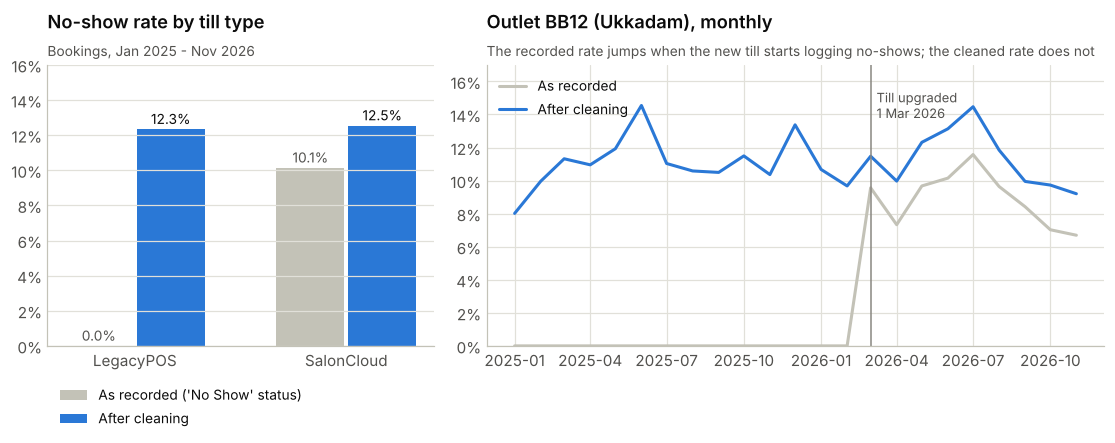

Recorded no-show rate 2.3% -> rebuilt 12.4%.


In [4]:
b = A[~A["is_walk_in"]]
rules = b.groupby("outcome_rule").agg(bookings=("appointment_id", "size")).assign(outcome=b.groupby("outcome_rule")["outcome"].first())
display(rules)
regime = cleaning.no_show_by_regime(A)
display(regime.style.format({c: "{:.2%}" for c in regime.columns if c != "bookings"} | {"bookings": "{:,}"}))
bb12 = b[b.outlet_id == "BB12"].assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp()) \
    .groupby("month").agg(raw_no_show_rate=("status_norm", lambda s: s.eq("no_show").mean()),
                          reconstructed_no_show_rate=("is_no_show", "mean")).reset_index()
fig = viz.no_show_reconstruction(regime, bb12); viz.save(fig, "01_no_show_reconstruction"); plt.show()
R["data"]["no_show"] = {"recorded_rate_legacy": f(regime.loc["LegacyPOS", "raw_no_show_rate"]),
                        "recorded_rate_cloud": f(regime.loc["SalonCloud", "raw_no_show_rate"]),
                        "rebuilt_rate_legacy": f(regime.loc["LegacyPOS", "reconstructed_no_show_rate"]),
                        "rebuilt_rate_cloud": f(regime.loc["SalonCloud", "reconstructed_no_show_rate"]),
                        "overall_rebuilt_rate": f(b["is_no_show"].mean()),
                        "overall_recorded_rate": f(b["status_norm"].eq("no_show").mean()),
                        "hidden_no_shows": int((b.status_norm.eq("cancelled") & b.is_no_show).sum())}
print(f"Recorded no-show rate {b['status_norm'].eq('no_show').mean():.1%} -> rebuilt {b['is_no_show'].mean():.1%}.")

**Check that the rebuild is right.** SalonCloud outlets record no-shows properly, so they act as a benchmark.
After cleaning, both till types show almost the same no-show rate (left). At BB12, the recorded rate jumps the
day it switched to SalonCloud, while the cleaned rate stays flat (right). If the rules were wrong, the
cleaned line would jump too.

,distinct spellings
method,
fuzzy (typo),1534
normalised alias,509
exact alias,152


,lines
service_name,
Haircut - Women,9403
Ladies Hair Cut,8708
HAIRCUT (F),7912
Women's Haircut,7516
haircut - women,197
ladies hair cut,183
HAIRCUT - WOMEN,177
Haircut - Women,175
women's haircut,163


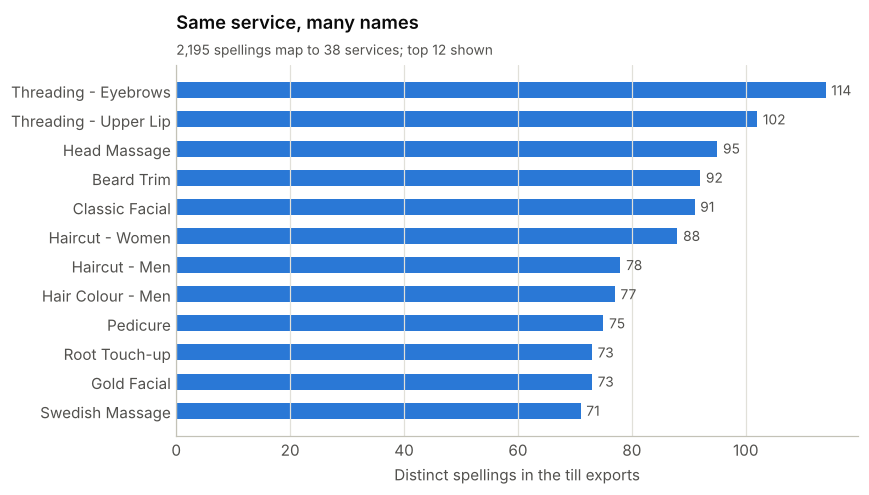

In [5]:
smap = res["service_map"]
display(smap["method"].value_counts().rename("distinct spellings").to_frame())
ex = res["service_lines"][res["service_lines"].canonical_service == "Haircut - Women"]["service_name"].value_counts().head(12)
display(ex.rename("lines").to_frame())
fig = viz.spellings_per_service(smap); viz.save(fig, "02_service_spellings"); plt.show()
R["data"]["services"] = {"spellings": int(len(smap)), "canonical": int(smap.canonical_service.nunique()),
                         "fuzzy": int((smap.method == "fuzzy (typo)").sum()),
                         "lines": int(len(res["service_lines"])), "mapped_share": 1.0}

### 1.2 Service names and walk-ins

**Service names.** Each till spells services its own way: *HAIRCUT (F)*, *Ladies Hair Cut* and
*Women's Haircut* are the same service. On top of that come typos (*Eebrow Threading*, *Shvae*). An alias
table built by reviewing names per outlet maps the known spellings. Fuzzy matching catches typos, with a
transposition-aware second pass for short words. As a final check, every fuzzy match has to sit inside the
normal price range for its service at that outlet.

**Walk-ins.** Most walk-ins carry no client ID. They stay in every outlet-level measure (visits, revenue,
the difference-in-differences). They are left out of client-level measures, because a visit can't be linked
to a person without an ID. That means client-level retention is a **lower bound**: regulars who sometimes
walk in look less loyal than they are. They are also not eligible for the A/B test, because a reminder
can't be sent without a phone number.

In [6]:
wk = A.groupby("channel").agg(appointments=("appointment_id", "size"), share_with_client_id=("client_known", "mean"))
display(wk.style.format({"appointments": "{:,}", "share_with_client_id": "{:.1%}"}))
xc = cleaning.crosscheck_experiment(res["experiment_raw"], A)
print(xc)
R["data"]["walk_ins"] = {"share_of_appointments": f(A.is_walk_in.mean()),
                         "share_without_id": f((A.is_walk_in & ~A.client_known).sum() / A.is_walk_in.sum())}
R["data"]["experiment_crosscheck"] = xc

,appointments,share_with_client_id
channel,,
App,"47,272",100.0%
Phone,"63,497",100.0%
Walk-in,"120,026",7.0%
WhatsApp,"72,499",100.0%


{'clients_checked': 6375, 'bookings_match_rate': 1.0, 'no_show_match_rate': 0.9987450980392157, 'no_shows_in_file': 960, 'no_shows_rebuilt': 968}


The experiment file comes from the reminder platform, which logs check-ins directly. When its no-show counts
are rebuilt from the cleaned appointments, they agree for 99.9% of clients. The small gap is genuine
cancellations whose timestamp was lost, which the rules have to treat as no-shows.

## 2. Part A: designing the A/B test (Smart Reminders)

**Initiative.** A WhatsApp reminder 24 hours before each booking (2 hours for same-day bookings) with
one-tap *Confirm* and *Reschedule* buttons.

**Hypothesis.** H0: reminders do not change the no-show rate. H1: they change it (two-sided test, because a
reminder could also annoy people into not showing). We expect a reduction.

**Unit of randomisation: the client.** The split is 50/50, using a salted hash of the client ID, so assignment
is stable and auditable. Randomising bookings instead would expose one client to both experiences.
**Eligible:** booked appointments (not walk-ins) by clients with a known ID who opted in to WhatsApp.
**Enrolment:** a client's first eligible booking scheduled in the test window. Outcomes are then followed for
28 days per client.

| Role | Metric | Why / threshold |
|---|---|---|
| **Primary** | **No-show rate** = no-shows (incl. <2h late cancels) / bookings, in the 28 days after enrolment | The mechanism reminders act on directly; measurable within weeks |
| Secondary | 45-day return rate (client completes a visit within 45 days) | The retention goal; too slow and noisy to be primary |
| Secondary | No-shows per client | Robust to reminders creating extra (rescheduled) bookings |
| Guardrail | Revenue per completed visit | Must not fall significantly by more than 3% |
| Guardrail | Completed visits per client | Must not fall significantly by more than 3% |
| Guardrail | WhatsApp opt-out rate | At most 3% in the treatment arm overall and at most 5% in any age band |
| Monitor | Advance-cancellation rate | Expected to **rise** (reschedules); fine if completed visits hold |

**Why not revenue per visit or retention as primary?** Reminders don't change what a client buys, so revenue
per visit is a guardrail, not the goal. Retention is the long-run goal, but it needs about 3.5 times the sample
(see below) and a 45-day wait for every client.

In [7]:
elig = pa.eligible_bookings(A, C)
PLAN_START, PLAN_DAYS = "2026-06-29", 28           # last full 4-week window whose 28-day follow-up ends before the design date (24 Aug)
coh = pa.planning_cohort(elig, PLAN_START, PLAN_DAYS, 28)
de = pa.design_effect(coh)
enrol_per_day = len(coh) / PLAN_DAYS
# 45-day return in the same cohort (for the secondary metric's baseline)
vk = V[V.client_known][["client_id", "date"]].merge(coh[["client_id", "enrol"]], on="client_id")
ret = vk[(vk.date > vk.enrol) & (vk.date <= vk.enrol + pd.Timedelta(days=45))].client_id.unique()
ret_base = coh.client_id.isin(ret).mean()
display(pd.Series({"planning window": f"{PLAN_START} + 28 days", "eligible clients enrolled": f"{len(coh):,}",
                   "enrolments per day": f"{enrol_per_day:.1f}", "bookings per client (28d)": f"{de['bookings_per_client']:.2f}",
                   "baseline no-show rate": f"{de['baseline_rate']:.2%}", "design effect": f"{de['design_effect']:.2f}",
                   "baseline 45-day return": f"{ret_base:.1%}"}).rename("value").to_frame())

,value
planning window,2026-06-29 + 28 days
eligible clients enrolled,"5,509"
enrolments per day,196.8
bookings per client (28d),1.27
baseline no-show rate,12.12%
design effect,1.10
baseline 45-day return,42.4%


**Choosing the minimum detectable effect (MDE).** We want to detect a drop of **2.5 percentage points**
(about 20% relative). That is roughly what reminder programmes deliver, and it is the smallest change worth
the operational rollout. The money is not the constraint: at about ₹0.50 a message (illustrative), the
programme pays for itself if it prevents even 0.1 pp of no-shows. Settings: α = 0.05 two-sided, 80% power.

**Clustering.** Some clients make several bookings, and their bookings are correlated. The design effect
measured on history (~1.1) inflates the sample size to cover that.

,value
bookings_per_arm_naive,"2,426.3"
bookings_per_arm,"2,669.9"
clients_per_arm,"2,095.2"
clients_total,"4,190.4"
days_needed,21.3
weeks_rounded_up,4.0


MDE (pp),relative MDE,clients per arm,enrolment days,weeks (rounded up)
1.5,12%,"6,066",61.7,9
2.0,16%,"3,344",34.0,5
2.5,21%,"2,095",21.3,4
3.0,25%,"1,423",14.5,3
3.5,29%,"1,022",10.4,2


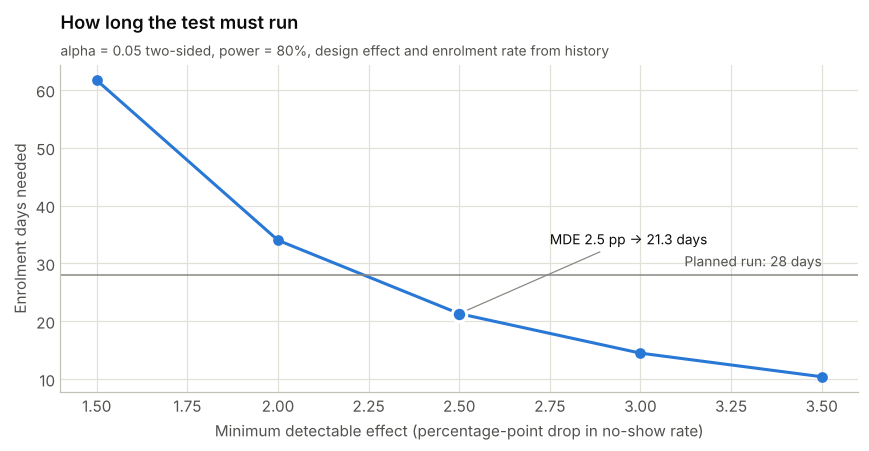

In [8]:
MDE, PLANNED_DAYS = 0.025, 28
plan = pa.plan(de["baseline_rate"], MDE, de["design_effect"], de["bookings_per_client"], enrol_per_day)
sens = pa.sensitivity_table(de["baseline_rate"], de["design_effect"], de["bookings_per_client"], enrol_per_day)
display(pd.Series(plan).to_frame("value").style.format("{:,.1f}"))
display(sens.style.format({"MDE (pp)": "{:.1f}", "relative MDE": "{:.0%}", "clients per arm": "{:,.0f}", "enrolment days": "{:.1f}"}).hide(axis="index"))
fig = viz.power_curve(sens, MDE * 100, plan["days_needed"], PLANNED_DAYS); viz.save(fig, "03_power_curve"); plt.show()

In [9]:
# What the planned sample can detect for the other metrics
n_arm = enrol_per_day * PLANNED_DAYS / 2
mde_ret = pa.mde_proportion(ret_base, n_arm)
# revenue per completed visit: delta-method SE from the planning cohort, scaled to the planned arm size
bk = A[~A.is_walk_in & A.client_known][["client_id", "appointment_id", "date", "is_completed"]].merge(coh[["client_id", "enrol"]], on="client_id")
bk = bk[(bk.date >= bk.enrol) & (bk.date < bk.enrol + pd.Timedelta(days=28))].merge(V[["appointment_id", "revenue"]], on="appointment_id", how="left")
pc = bk.groupby("client_id").agg(rev=("revenue", "sum"), done=("is_completed", "sum"))
pc = pc[pc.done > 0]
rpv0 = pc.rev.sum() / pc.done.sum()
se_rpv = math.sqrt(2 * pa.ratio_delta_var(pc.rev.to_numpy(float), pc.done.to_numpy(float)) * len(pc) / (n_arm * len(pc) / len(coh)))
mde_rpv = 2.8 * se_rpv / rpv0
print(f"Planned run: {PLANNED_DAYS} days -> ~{n_arm:,.0f} clients per arm")
print(f"MDE for 45-day return: {mde_ret*100:.1f} pp (baseline {ret_base:.1%})  -> retention would need ~{(mde_ret/0.02)**2:.1f}x the sample to detect 2 pp")
print(f"MDE for revenue per visit: {mde_rpv:.1%} of Rs {rpv0:,.0f}  -> guardrails detect large harm, they cannot prove 'no change'")

Planned run: 28 days -> ~2,754 clients per arm
MDE for 45-day return: 3.7 pp (baseline 42.4%)  -> retention would need ~3.5x the sample to detect 2 pp
MDE for revenue per visit: 9.4% of Rs 1,183  -> guardrails detect large harm, they cannot prove 'no change'


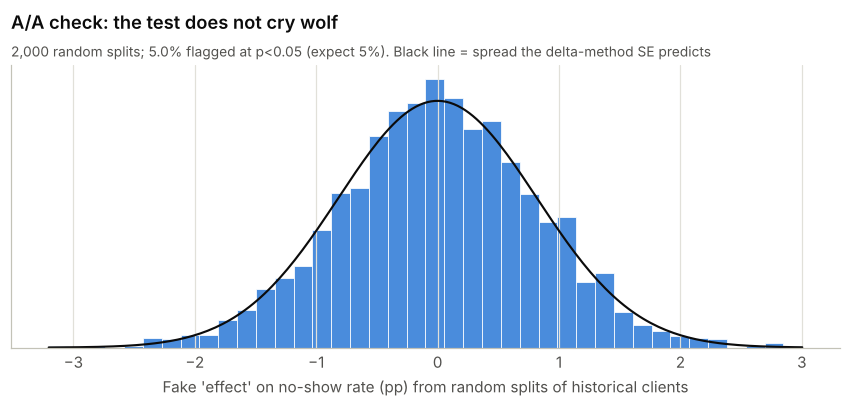

A/A false-positive rate 5.0% (target 5%); empirical SD 0.82 pp vs delta-method SE 0.82 pp


In [10]:
aa = pa.aa_simulation(coh, n_sims=2000)
fig = viz.aa_hist(aa["diffs"], aa["mean_delta_se"], aa["false_positive_rate"]); viz.save(fig, "04_aa_test"); plt.show()
print(f"A/A false-positive rate {aa['false_positive_rate']:.1%} (target 5%); empirical SD {aa['empirical_sd']*100:.2f} pp vs delta-method SE {aa['mean_delta_se']*100:.2f} pp")
R["design"] = {"planning_window_start": PLAN_START, "planning_clients": int(len(coh)), "enrol_per_day": f(enrol_per_day),
               "baseline_no_show": f(de["baseline_rate"]), "bookings_per_client": f(de["bookings_per_client"]),
               "design_effect": f(de["design_effect"]), "mde_pp": MDE * 100, "mde_rel": f(MDE / de["baseline_rate"]),
               "bookings_per_arm_naive": f(plan["bookings_per_arm_naive"]), "bookings_per_arm": f(plan["bookings_per_arm"]),
               "clients_per_arm": f(plan["clients_per_arm"]), "days_needed": f(plan["days_needed"]),
               "planned_days": PLANNED_DAYS, "n_arm_planned": f(n_arm), "baseline_return_45d": f(ret_base),
               "mde_return_pp": f(mde_ret * 100), "baseline_rpv": f(rpv0), "mde_rpv_rel": f(mde_rpv),
               "aa_fpr": f(aa["false_positive_rate"]), "aa_sims": 2000, "aa_sd": f(aa["empirical_sd"]), "aa_se": f(aa["mean_delta_se"]),
               "sensitivity": sens.round(3).to_dict(orient="records")}

**Duration.** The power analysis needs about 21 enrolment days. We plan **4 full weeks (31 Aug to 27 Sep 2026)**:
- Rounding up to whole weeks covers the weekly cycle (Tuesday dip, weekend peak).
- Four weeks spans a month-start payday.
- It dilutes any novelty effect.

The primary metric is read 28 days after the last enrolment; the 45-day return is read on 11 Nov.

**Pre-registered decision rules**
- **Validity gate:** sample-ratio-mismatch (SRM) test p < 0.001 chain-wide or in any outlet (Bonferroni-corrected) → investigate before reading results.
- **GO:** primary 95% CI entirely below 0 **and** no chain-level guardrail breached. A segment breach means a targeted fix, not a stop.
- **NO-GO:** primary CI entirely above 0, **or** any chain-level guardrail breached (significantly worse and beyond its tolerance).
- **EXTEND:** primary CI includes 0. Run longer, up to the sample needed for the observed effect, or stop if even the CI's best case is below the MDE.
- **Fixed horizon:** no peeking. Segments are pre-specified and Holm-corrected, and are treated as hypotheses for follow-up.

## 3. Part B: analysing the experiment

### 3.1 Is the experiment valid? Sample ratio mismatch

In [11]:
e, elog = ab.prepare_experiment(res["experiment_raw"])
e = ab.add_pre_period(e, A, V, C)
print(elog)
srm_all = ab.srm(int((e.treat == 0).sum()), int((e.treat == 1).sum()))
srm_out = ab.srm_by(e, "outlet_id").sort_values("p_value")
print(f"Chain-wide: control {srm_all['control']:,} vs treatment {srm_all['treatment']:,}, p = {srm_all['p_value']:.3f}")
display(srm_out.head(5).style.format({"treatment_share": "{:.1%}", "chi2": "{:.2f}", "p_value": "{:.2e}", "p_bonferroni": "{:.2e}"}))

{'rows_in_file': 6435, 'variant_labels_fixed': 171, 'crossover_clients': 30, 'crossover_rows': 60, 'clients_analysed': 6375}
Chain-wide: control 3,225 vs treatment 3,150, p = 0.348


,control,treatment,treatment_share,chi2,p_value,p_bonferroni
outlet_id,,,,,,
BB16,261,132,33.6%,42.34,7.66e-11,1.68e-09
BB19,214,167,43.8%,5.80,1.60e-02,3.53e-01
BB18,151,190,55.7%,4.46,3.47e-02,7.63e-01
BB11,139,117,45.7%,1.89,1.69e-01,1.00e+00
BB20,181,208,53.5%,1.87,1.71e-01,1.00e+00


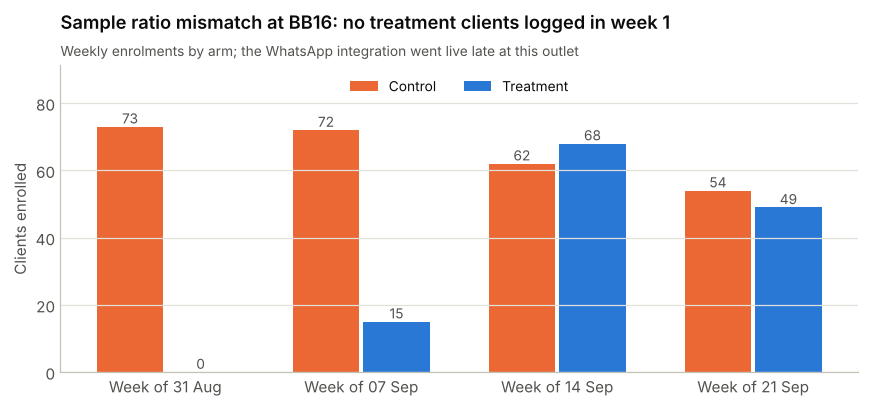

After excluding BB16: control 2,964 vs treatment 3,018, p = 0.49


In [12]:
bad = srm_out.index[0]
wk = e[e.outlet_id == bad].assign(week=lambda d: d["enrolled_on"].dt.to_period("W-SUN").dt.start_time) \
    .groupby(["week", "treat"]).size().unstack().rename(columns={0: "control", 1: "treatment"}).fillna(0).sort_index()
wk.index = ["Week of " + d.strftime("%d %b") for d in wk.index]
fig = viz.srm_by_week(wk, bad); viz.save(fig, "05_srm_bb16"); plt.show()
ea = e[e.outlet_id != bad].copy()
srm_after = ab.srm(int((ea.treat == 0).sum()), int((ea.treat == 1).sum()))
print(f"After excluding {bad}: control {srm_after['control']:,} vs treatment {srm_after['treatment']:,}, p = {srm_after['p_value']:.2f}")
R["srm"] = {"overall": srm_all, "outlet": bad, "outlet_control": int(srm_out.loc[bad, "control"]),
            "outlet_treatment": int(srm_out.loc[bad, "treatment"]), "outlet_p": f(srm_out.loc[bad, "p_value"]),
            "after": srm_after, "next_worst_p_bonf": f(srm_out["p_bonferroni"].iloc[1]), "prep": elog}

The chain-wide SRM test passes (p ≈ 0.35), but the per-outlet check does not. At **BB16 (RS Puram)**, no
treatment clients were logged in the first week and only a few in the second; the WhatsApp integration went
live late there. The treatment clients who did make it into the data at BB16 are only the late enrollees, a
different kind of client from the full control group. So **BB16 is excluded from both arms**. Its results
appear as a sensitivity check below. After the exclusion, the ratio is clean.

*Lesson: a passing chain-wide SRM test can hide a broken outlet. Always check SRM by outlet and by week.*

### 3.2 Were the arms comparable before the test?

covariate,level,control,treatment,smd,p_value
pre_bookings,,2.522,2.518,-0.002,0.942
pre_no_shows,,0.277,0.269,-0.011,0.662
pre_visits,,2.132,2.135,+0.002,0.944
pre_revenue,,2437.476,2399.131,-0.013,0.626
days_since_last_visit,,81.842,83.577,+0.028,0.272
tenure_days,,237.492,237.673,+0.001,0.977
is_new,,0.215,0.214,-0.002,0.935
enrol_booking_lead_days,,3.953,3.835,-0.027,0.296
enrol_evening,,0.299,0.310,+0.024,0.360
enrol_weekend,,0.321,0.310,-0.023,0.373


Largest |SMD| = 0.075; joint test (can covariates predict assignment?) LR = 28.3, df = 21, p = 0.13


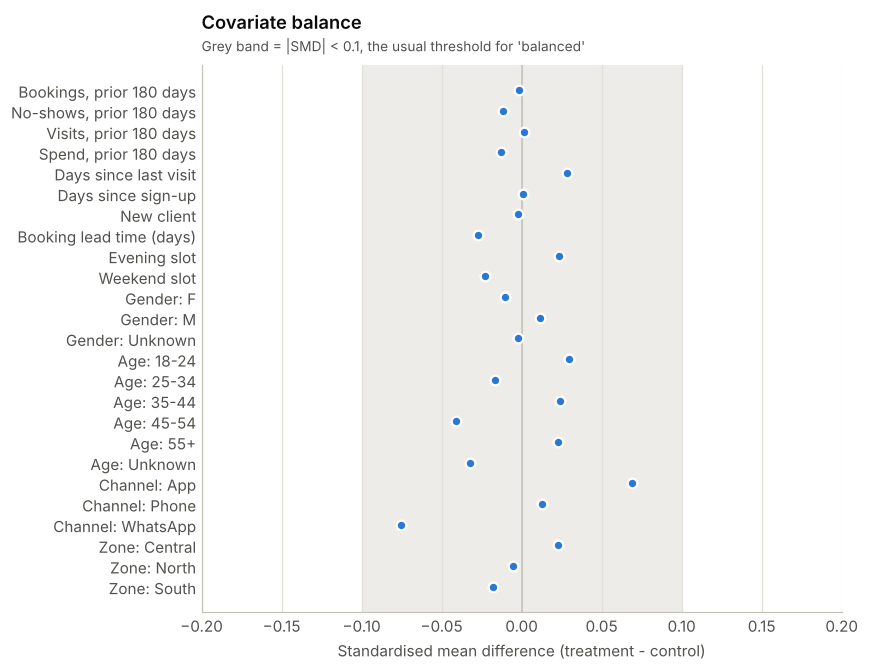

In [13]:
# features of the enrolling booking itself (fixed before any reminder was sent)
eb = A[~A.is_walk_in & A.client_known][["client_id", "date", "hour", "scheduled_start"]] \
    .merge(ea[["client_id", "enrolled_on"]], left_on=["client_id", "date"], right_on=["client_id", "enrolled_on"]) \
    .sort_values("scheduled_start").drop_duplicates("client_id")
eb = eb.assign(enrol_evening=eb.hour.ge(18).astype(int), enrol_morning=eb.hour.le(10).astype(int),
               enrol_weekend=eb.scheduled_start.dt.dayofweek.ge(5).astype(int))
ea = ea.merge(eb[["client_id", "enrol_evening", "enrol_morning", "enrol_weekend"]], on="client_id", how="left")
NUM = ["pre_bookings", "pre_no_shows", "pre_visits", "pre_revenue", "days_since_last_visit", "tenure_days", "is_new",
       "enrol_booking_lead_days", "enrol_evening", "enrol_weekend"]
CAT = ["gender", "age_band", "enrol_booking_channel", "zone"]
bt = ab.balance_table(ea, NUM, CAT)
omni = ab.omnibus_balance(ea, NUM, CAT)
display(bt.style.format({"control": "{:.3f}", "treatment": "{:.3f}", "smd": "{:+.3f}", "p_value": "{:.3f}"}).hide(axis="index"))
print(f"Largest |SMD| = {bt.smd.abs().max():.3f}; joint test (can covariates predict assignment?) LR = {omni['lr_stat']:.1f}, df = {omni['df']}, p = {omni['p_value']:.2f}")
fig = viz.love_plot(bt); viz.save(fig, "06_balance"); plt.show()
bt.to_csv(TABLES / "balance.csv", index=False)
R["balance"] = {"max_abs_smd": f(bt.smd.abs().max()), "omnibus_p": f(omni["p_value"]), "omnibus_lr": f(omni["lr_stat"]),
                "omnibus_df": omni["df"], "worst": bt.loc[bt.smd.abs().idxmax(), ["covariate", "level"]].tolist(),
                "channel_p": f(bt.loc[bt.covariate == "enrol_booking_channel", "p_value"].iloc[0])}

Every standardised difference is below the usual 0.1 threshold, and covariates cannot predict assignment.
Booking channel shows a small chance imbalance: slightly more app bookers in treatment. App users already get
push notifications, so this would, if anything, *understate* the effect. The regression-adjusted estimate
in §3.6 controls for it.

### 3.3 Primary result: no-show rate

In [14]:
prim = ab.ratio_effect(ea, "no_shows_28d", "bookings_28d")
boot = ab.bootstrap_effect(ea, "no_shows_28d", "bookings_28d", B=10000)
welch = ab.mean_effect(ea, "no_show_rate")
tbl = pd.DataFrame([
    {"method": "Delta method (booking-weighted, clients as units)", "control": prim["control"], "treatment": prim["treatment"], "diff": prim["diff"], "ci_low": prim["ci_low"], "ci_high": prim["ci_high"], "p_value": prim["p_value"]},
    {"method": "Client bootstrap, 10,000 resamples", "control": prim["control"], "treatment": prim["treatment"], "diff": boot["diff"], "ci_low": boot["ci_low"], "ci_high": boot["ci_high"], "p_value": boot["p_value"]},
    {"method": "Welch t-test on each client's own rate", "control": welch["control"], "treatment": welch["treatment"], "diff": welch["diff"], "ci_low": welch["ci_low"], "ci_high": welch["ci_high"], "p_value": welch["p_value"]},
])
display(tbl.style.format({c: "{:.2%}" for c in ["control", "treatment", "diff", "ci_low", "ci_high"]} | {"p_value": "{:.4f}"}).hide(axis="index"))
print(f"No-show rate {prim['control']:.2%} -> {prim['treatment']:.2%}: {fmt_ci(prim)}, relative {prim['rel']:+.1%} "
      f"(95% CI {prim['rel_ci_low']:+.1%} to {prim['rel_ci_high']:+.1%}), p = {prim['p_value']:.4f}")
R["primary"] = {**{k: f(v) if isinstance(v, (float, np.floating)) else v for k, v in prim.items()},
                "boot_ci_low": f(boot["ci_low"]), "boot_ci_high": f(boot["ci_high"]), "boot_p": f(boot["p_value"]),
                "welch_diff": f(welch["diff"]), "welch_ci_low": f(welch["ci_low"]), "welch_ci_high": f(welch["ci_high"]), "welch_p": f(welch["p_value"])}

method,control,treatment,diff,ci_low,ci_high,p_value
"Delta method (booking-weighted, clients as units)",12.37%,9.85%,-2.52%,-3.97%,-1.08%,0.0006
"Client bootstrap, 10,000 resamples",12.37%,9.85%,-2.52%,-4.00%,-1.09%,0.0020
Welch t-test on each client's own rate,10.62%,8.59%,-2.02%,-3.35%,-0.70%,0.0028


No-show rate 12.37% -> 9.85%: -2.52 pp (95% CI -3.97 to -1.08), relative -20.4% (95% CI -30.1% to -9.3%), p = 0.0006


All three methods agree: reminders cut the no-show rate by about **2.5 percentage points (~20% relative)**,
roughly the effect the test was designed to detect, and the interval excludes zero.

### 3.4 Secondary metrics and guardrails

label,kind,control,treatment,diff,ci_low,ci_high,p_value,rel,rel_ci_low,rel_ci_high
No-show rate,primary,0.1237,0.0985,-0.0252,-0.0397,-0.0108,0.0006,-20.4%,-30.1%,-9.3%
No-shows per client,secondary,0.1673,0.1355,-0.0318,-0.0524,-0.0113,0.0024,-19.0%,-31.3%,-6.7%
45-day return rate,secondary,0.5067,0.5195,+0.0128,-0.0125,+0.0381,0.3220,+2.5%,-2.5%,+7.5%
Revenue per completed visit,guardrail,"1,526.4097","1,524.1861",-2.2236,-94.7516,+90.3044,0.9624,-0.1%,-6.0%,+6.1%
Completed visits per client,guardrail,1.0928,1.1093,+0.0166,-0.0106,+0.0437,0.2318,+1.5%,-1.0%,+4.0%
Advance-cancellation rate,monitor,0.0686,0.0954,+0.0268,+0.0145,+0.0390,0.0000,+39.0%,+19.2%,+62.2%
Bookings per client,monitor,1.3529,1.3761,+0.0232,-0.0059,+0.0523,0.1185,+1.7%,-0.4%,+3.9%


Opt-out rate: control 0.40% (SMS 'STOP'), treatment 1.49% (threshold 3%)


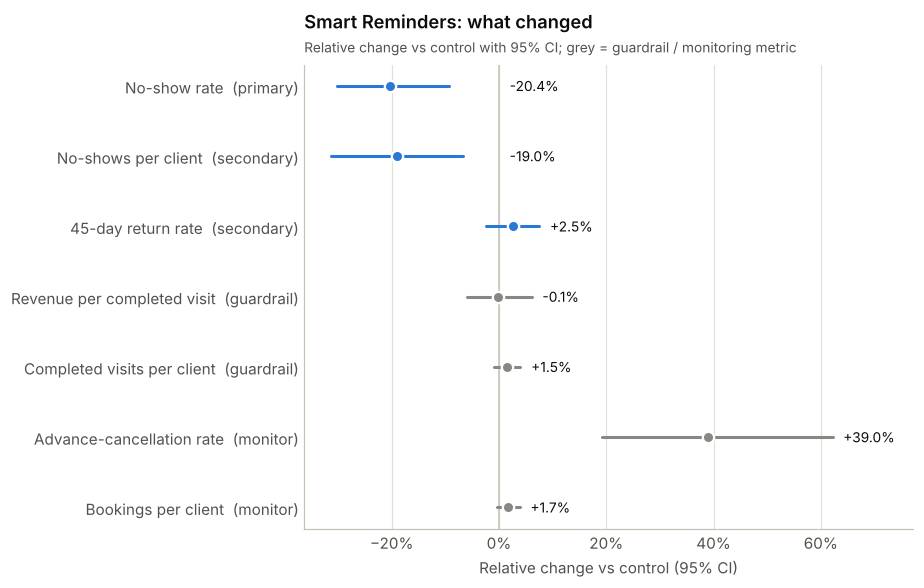

In [15]:
rows = []
def add(label, kind, r):
    rows.append({"label": label, "kind": kind, **{k: r[k] for k in ["control", "treatment", "diff", "ci_low", "ci_high", "p_value"]},
                 "rel": r.get("rel", r["diff"] / r["control"]),
                 "rel_ci_low": r.get("rel_ci_low", r["ci_low"] / r["control"]), "rel_ci_high": r.get("rel_ci_high", r["ci_high"] / r["control"])})
add("No-show rate", "primary", prim)
add("No-shows per client", "secondary", ab.mean_effect(ea, "no_shows_28d"))
add("45-day return rate", "secondary", ab.mean_effect(ea, "returned_45d"))
add("Revenue per completed visit", "guardrail", ab.ratio_effect(ea, "revenue_28d", "completed_visits_28d"))
add("Completed visits per client", "guardrail", ab.mean_effect(ea, "completed_visits_28d"))
add("Advance-cancellation rate", "monitor", ab.ratio_effect(ea, "cancellations_28d", "bookings_28d"))
add("Bookings per client", "monitor", ab.mean_effect(ea, "bookings_28d"))
eff = pd.DataFrame(rows)
optout = ab.mean_effect(ea, "opted_out")
display(eff.style.format({"control": "{:,.4f}", "treatment": "{:,.4f}", "diff": "{:+,.4f}", "ci_low": "{:+,.4f}", "ci_high": "{:+,.4f}",
                          "p_value": "{:.4f}", "rel": "{:+.1%}", "rel_ci_low": "{:+.1%}", "rel_ci_high": "{:+.1%}"}).hide(axis="index"))
print(f"Opt-out rate: control {optout['control']:.2%} (SMS 'STOP'), treatment {optout['treatment']:.2%} (threshold 3%)")
fig = viz.effects_forest(eff, "Smart Reminders: what changed", "Relative change vs control with 95% CI; grey = guardrail / monitoring metric")
viz.save(fig, "07_ab_effects"); plt.show()
eff.to_csv(TABLES / "ab_effects.csv", index=False)
R["effects"] = eff.set_index("label").apply(lambda r: {k: f(v) if not isinstance(v, str) else v for k, v in r.items()}, axis=1).to_dict()
R["optout"] = {"control": f(optout["control"]), "treatment": f(optout["treatment"]), "diff": f(optout["diff"]),
               "ci_low": f(optout["ci_low"]), "ci_high": f(optout["ci_high"])}

- **Revenue per visit:** flat. Its interval is wide (about ±6%), so this guardrail can detect large harm but
  cannot prove there is no change.
- **Completed visits per client:** flat to slightly up.
- **Cancellations:** rise, as expected. Would-be no-shows tap *Reschedule* instead, which frees the slot at
  least 20 hours ahead.
- **45-day return:** positive but not significant. Part of any lift is mechanical, because a rescheduled
  visit counts as a return.

### 3.5 Robustness: including BB16, and the effect on clients who actually got the message

In [16]:
inc = ab.ratio_effect(e, "no_shows_28d", "bookings_28d")
cc = ab.cace(ea, "no_shows_28d", "bookings_28d")
print(f"Including {bad} anyway: {fmt_ci(inc)}")
print(f"Delivered to {cc['delivery_rate']:.1%} of treatment clients. Effect on clients who received the reminder (CACE): "
      f"{cc['cace']*100:+.2f} pp (95% CI {cc['ci_low']*100:+.2f} to {cc['ci_high']*100:+.2f})")
R["robust"] = {"incl_bb16_diff": f(inc["diff"]), "incl_bb16_ci_low": f(inc["ci_low"]), "incl_bb16_ci_high": f(inc["ci_high"]),
               "delivery_rate": f(cc["delivery_rate"]), "cace": f(cc["cace"]), "cace_ci_low": f(cc["ci_low"]), "cace_ci_high": f(cc["ci_high"])}

Including BB16 anyway: -2.46 pp (95% CI -3.86 to -1.07)
Delivered to 91.9% of treatment clients. Effect on clients who received the reminder (CACE): -2.74 pp (95% CI -4.31 to -1.15)


### 3.6 Who gained and who lost (pre-specified segments)

dimension,segment,clients,control,treatment,diff,ci_low,ci_high,p_value,p_holm
Age band,18-24,1035,16.31%,12.21%,-4.09%,-8.01%,-0.18%,0.041,0.568
Age band,25-34,1985,13.51%,10.75%,-2.76%,-5.35%,-0.16%,0.037,0.558
Age band,35-44,1441,11.24%,8.99%,-2.25%,-5.07%,+0.57%,0.118,0.931
Age band,45-54,770,10.23%,7.31%,-2.92%,-6.40%,+0.56%,0.100,0.931
Age band,55+,445,6.16%,10.09%,+3.94%,-0.58%,+8.45%,0.087,0.931
Booking channel,App,1521,13.35%,11.74%,-1.61%,-4.62%,+1.40%,0.294,1.000
Booking channel,Phone,1961,12.05%,8.49%,-3.57%,-6.04%,-1.10%,0.005,0.089
Booking channel,WhatsApp,2194,12.26%,10.23%,-2.03%,-4.40%,+0.34%,0.093,0.931
Booking lead time,Same day,1018,10.18%,9.08%,-1.10%,-4.33%,+2.13%,0.505,1.000
Booking lead time,Next day,905,9.46%,7.63%,-1.83%,-5.05%,+1.39%,0.265,1.000


dimension,segments,Q,df,p_heterogeneity
Age band,5,8.34,4,0.080
Booking channel,3,1.20,2,0.548
Booking lead time,4,1.33,3,0.723
No-show history,3,1.45,2,0.484
Gender,2,0.03,1,0.873
Zone,3,3.81,2,0.149


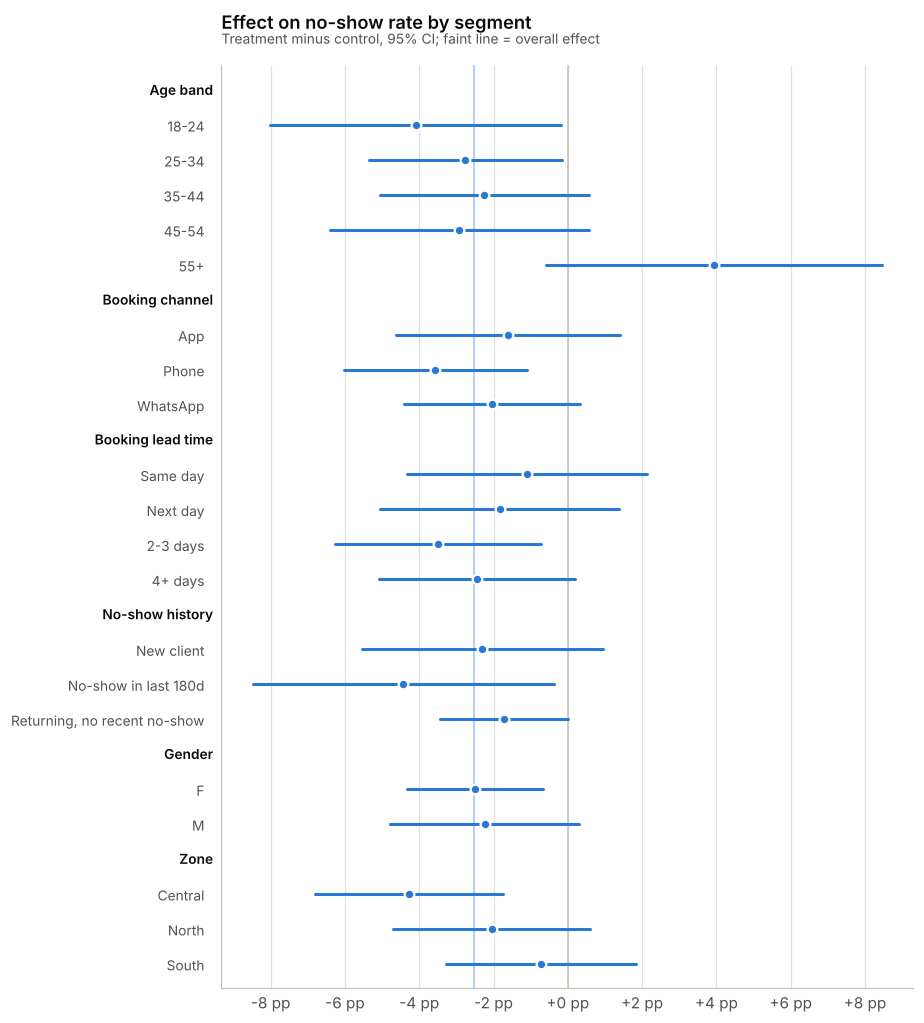

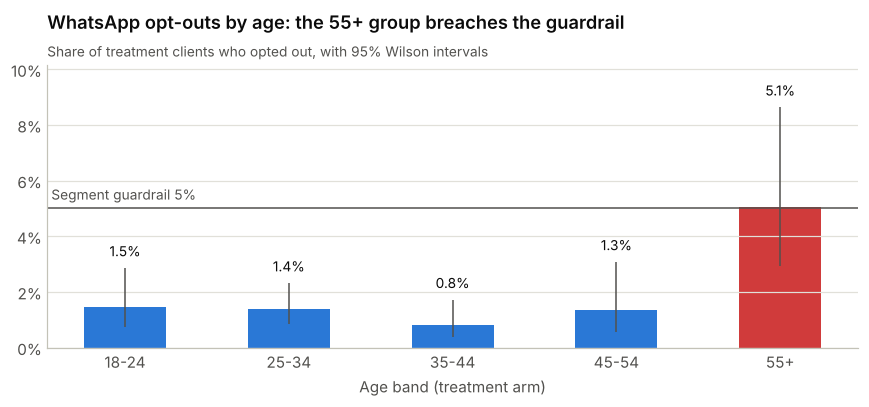

In [17]:
DIMS = {"age_band": "Age band", "enrol_booking_channel": "Booking channel", "seg_lead": "Booking lead time",
        "seg_history": "No-show history", "gender": "Gender", "zone": "Zone"}
order = {"seg_lead": ["Same day", "Next day", "2-3 days", "4+ days"]}
seg, het = ab.segment_effects(ea[(ea.age_band != "Unknown") & (ea.gender != "Unknown")], DIMS)
seg["_o"] = seg.apply(lambda r: order.get({v: k for k, v in DIMS.items()}[r["dimension"]], []).index(r["segment"])
                      if r["segment"] in order.get({v: k for k, v in DIMS.items()}[r["dimension"]], []) else 0, axis=1)
seg = seg.sort_values(["dimension", "_o", "segment"], key=lambda s: s.map({d: i for i, d in enumerate(DIMS.values())}) if s.name == "dimension" else s).drop(columns="_o")
display(seg.style.format({"control": "{:.2%}", "treatment": "{:.2%}", "diff": "{:+.2%}", "ci_low": "{:+.2%}", "ci_high": "{:+.2%}", "p_value": "{:.3f}", "p_holm": "{:.3f}"}).hide(axis="index"))
display(het.style.format({"Q": "{:.2f}", "p_heterogeneity": "{:.3f}"}).hide(axis="index"))
fig = viz.segment_forest(seg, prim["diff"], "Effect on no-show rate by segment", "Treatment minus control, 95% CI; faint line = overall effect")
viz.save(fig, "08_segments"); plt.show()
opt_age = ab.segment_rates(ea[ea.treat == 1], "age_band", "opted_out")
fig = viz.optout_by_age(opt_age, 0.05); viz.save(fig, "09_optout_by_age"); plt.show()
seg.to_csv(TABLES / "ab_segments.csv", index=False)
R["segments"] = {"table": seg.round(5).to_dict(orient="records"), "heterogeneity": het.round(4).to_dict(orient="records"),
                 "optout_by_age": opt_age.round(4).to_dict(orient="records")}

- **Gained most:** clients with a recent no-show, younger clients, and bookings made 2 or more days ahead,
  which are the ones most likely to forget.
- **Gained least:** same-day and app bookings. The reminder has little to add for a booking made hours
  earlier or for someone who already gets an app push.
- **Lost: clients aged 55 and over.** No reduction in no-shows (the point estimate even goes the wrong way)
  and an opt-out rate of about 5%, breaching the 5% segment guardrail. They should get a phone or SMS
  reminder instead.

Two different questions are tested here:
- **Holm-adjusted p-values** ask whether each segment's effect differs from zero. Only Central clears that
  bar on its own.
- **Heterogeneity tests** ask whether segments differ *from each other*. None do significantly; the lowest is
  age, p ≈ 0.08.

So the pattern above is a set of hypotheses to confirm, not findings to act on alone. The exception is the
opt-out guardrail, which is a harm signal.

### 3.7 Stretch: CUPED and regression adjustment

CUPED subtracts the part of each client's outcome that their own pre-test history predicts. Assignment is
random, so this removes noise without adding bias. Regression adjustment generalises it to several
pre-treatment covariates.

label,diff,ci_low,ci_high
Per-client rate: unadjusted,-2.023%,-3.350%,-0.697%
Per-client rate: CUPED,-2.129%,-3.441%,-0.816%
Booking-weighted: unadjusted,-2.521%,-3.966%,-1.075%
Booking-weighted: regression-adjusted,-2.623%,-4.025%,-1.220%


metric,variance_reduction
No-show rate (primary),5.9%
45-day return,4.7%
Completed visits / client,4.6%
Revenue / client (winsorised),14.8%


Classic CUPED: theta = 0.199, pre/post correlation = 0.141, variance reduction = 2.0%
Regression adjustment: variance reduction 5.9% -> enrolment needed 21.3 -> 20.1 days, i.e. 4 -> 3 whole weeks (7 days shorter than the 28-day run)


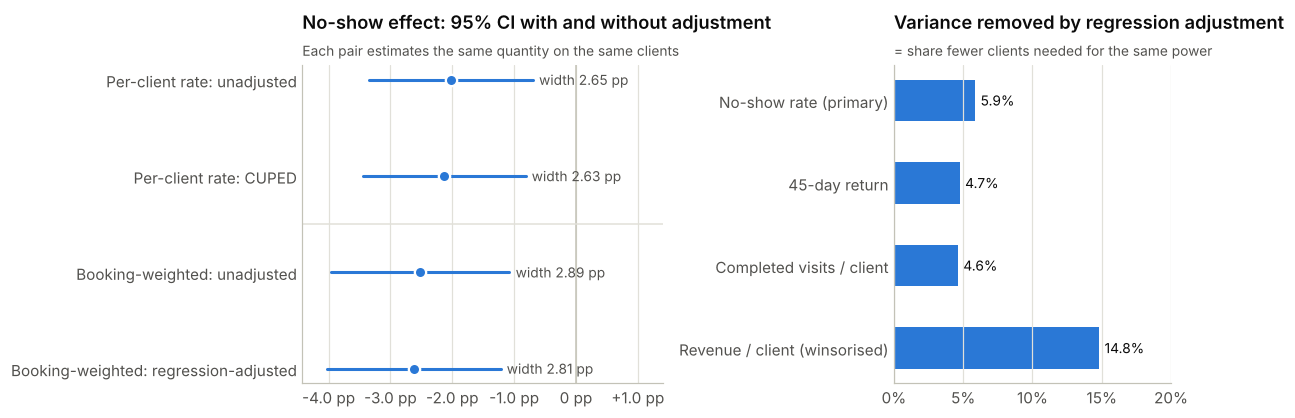

In [18]:
ea["pre_ns_f"] = ea["pre_no_show_rate"].fillna(ea["pre_no_show_rate"].mean())
cup = vr.cuped(ea, "no_show_rate", "pre_no_show_rate")
COV_P = ["pre_ns_f", "pre_no_shows", "pre_bookings", "is_new", "enrol_evening", "enrol_morning", "enrol_weekend"]
CAT_P = ["seg_lead", "enrol_booking_channel", "age_band"]
ra = vr.regression_adjusted(ea, "no_show_rate", COV_P, weights="bookings_28d", categorical=CAT_P)
# revenue per client (winsorised at the 99th percentile - bridal bookings dominate the variance otherwise)
vv = V[V.client_known][["client_id", "date", "segment"]].merge(ea[["client_id", "enrolled_on"]], on="client_id")
vv = vv[(vv.date < vv.enrolled_on) & (vv.date >= vv.enrolled_on - pd.Timedelta(days=180))]
ea = ea.join(vv.groupby("client_id")["segment"].agg(lambda s: s.value_counts().index[0]).rename("fav_segment"), on="client_id")
ea["fav_segment"] = ea["fav_segment"].fillna("None")
ea["rev_w"] = ea.revenue_28d.clip(upper=ea.revenue_28d.quantile(0.99)); ea["pre_rev_w"] = ea.pre_revenue.clip(upper=ea.pre_revenue.quantile(0.99))
ra_rev = vr.regression_adjusted(ea, "rev_w", ["pre_rev_w", "pre_visits", "is_new", "days_since_last_visit"], categorical=["fav_segment", "enrol_booking_channel", "gender"])
ra_ret = vr.regression_adjusted(ea, "returned_45d", ["pre_visits", "pre_bookings", "is_new", "days_since_last_visit", "tenure_days"], categorical=["fav_segment", "enrol_booking_channel"])
ra_vis = vr.regression_adjusted(ea, "completed_visits_28d", ["pre_visits", "pre_bookings", "is_new", "days_since_last_visit"], categorical=["fav_segment"])
short = vr.shorter_test(plan["days_needed"], ra["variance_reduction"], PLANNED_DAYS)
ci_rows = pd.DataFrame([
    {"label": "Per-client rate: unadjusted", **cup["unadjusted"]},
    {"label": "Per-client rate: CUPED", **cup["cuped"]},
    {"label": "Booking-weighted: unadjusted", **{k: ra["unadjusted"][k] for k in ["diff", "ci_low", "ci_high"]}},
    {"label": "Booking-weighted: regression-adjusted", **{k: ra["adjusted"][k] for k in ["diff", "ci_low", "ci_high"]}}])
vr_rows = pd.DataFrame([{"metric": "No-show rate (primary)", "variance_reduction": ra["variance_reduction"]},
                        {"metric": "45-day return", "variance_reduction": ra_ret["variance_reduction"]},
                        {"metric": "Completed visits / client", "variance_reduction": ra_vis["variance_reduction"]},
                        {"metric": "Revenue / client (winsorised)", "variance_reduction": ra_rev["variance_reduction"]}])
display(ci_rows[["label", "diff", "ci_low", "ci_high"]].style.format({c: "{:+.3%}" for c in ["diff", "ci_low", "ci_high"]}).hide(axis="index"))
display(vr_rows.style.format({"variance_reduction": "{:.1%}"}).hide(axis="index"))
print(f"Classic CUPED: theta = {cup['theta']:.3f}, pre/post correlation = {cup['rho']:.3f}, variance reduction = {cup['variance_reduction']:.1%}")
print(f"Regression adjustment: variance reduction {ra['variance_reduction']:.1%} -> enrolment needed {short['days_needed_unadjusted']:.1f} -> "
      f"{short['days_needed_adjusted']:.1f} days, i.e. {short['weeks_unadjusted']} -> {short['weeks_adjusted']} whole weeks "
      f"({short['days_saved_vs_plan']} days shorter than the 28-day run)")
fig = viz.cuped_chart(ci_rows, vr_rows); viz.save(fig, "10_cuped"); plt.show()
R["cuped"] = {"theta": f(cup["theta"]), "rho": f(cup["rho"]), "cuped_vr": f(cup["variance_reduction"]),
              "cuped_diff": f(cup["cuped"]["diff"]), "cuped_ci_low": f(cup["cuped"]["ci_low"]), "cuped_ci_high": f(cup["cuped"]["ci_high"]),
              "ra_vr": f(ra["variance_reduction"]), "ra_diff": f(ra["adjusted"]["diff"]), "ra_ci_low": f(ra["adjusted"]["ci_low"]),
              "ra_ci_high": f(ra["adjusted"]["ci_high"]), "ra_p": f(ra["adjusted"]["p_value"]),
              "unadj_ci_width": f(ra["unadjusted"]["ci_high"] - ra["unadjusted"]["ci_low"]),
              "ra_ci_width": f(ra["adjusted"]["ci_high"] - ra["adjusted"]["ci_low"]),
              "vr_return": f(ra_ret["variance_reduction"]), "vr_visits": f(ra_vis["variance_reduction"]), "vr_revenue": f(ra_rev["variance_reduction"]),
              "days_unadj": f(short["days_needed_unadjusted"]), "days_adj": f(short["days_needed_adjusted"]),
              "weeks_unadj": short["weeks_unadjusted"], "weeks_adj": short["weeks_adjusted"], "days_saved": short["days_saved_vs_plan"],
              "covariates": ra["covariates"]}

**How much shorter could the test have been?** For the primary metric, regression adjustment removes about 6%
of the variance. Enrolment needed drops from ~21.3 to ~20.1 days, which fits inside **three whole weeks
instead of four**. In continuous terms, though, it is only ~6% fewer clients.

The gain is small because no-shows are rare yes/no events and most clients book about once in 4 weeks, so a
client's history says little about one future booking. Variance reduction pays off much more for spend
metrics: ~15% for revenue per client, where history is a strong predictor.

### 3.8 Decision on Smart Reminders

In [19]:
g_rev, g_vis = eff.set_index("label").loc["Revenue per completed visit"], eff.set_index("label").loc["Completed visits per client"]
breach = {"Revenue per completed visit": bool(g_rev.rel_ci_high < 0 and g_rev.rel < -0.03),
          "Completed visits per client": bool(g_vis.rel_ci_high < 0 and g_vis.rel < -0.03),
          "Opt-out rate (overall <= 3%)": bool(optout["treatment"] > 0.03)}
seg_breach = opt_age[(opt_age.rate > 0.05) & (opt_age.segment != "Unknown")]["segment"].tolist()
decision = "GO" if (prim["ci_high"] < 0 and not any(breach.values())) else ("NO-GO" if prim["ci_low"] > 0 or any(breach.values()) else "EXTEND")
display(pd.Series(breach, name="breached").to_frame())
print(f"Primary CI entirely below zero: {prim['ci_high'] < 0}.  Segment guardrail breaches: {seg_breach}")
print(f"DECISION (pre-registered rules): {decision}")
R["ab_decision"] = {"decision": decision, "guardrail_breach": breach, "segment_breaches": seg_breach}

,breached
Revenue per completed visit,False
Completed visits per client,False
Opt-out rate (overall <= 3%),False


Primary CI entirely below zero: True.  Segment guardrail breaches: ['55+']
DECISION (pre-registered rules): GO


## 4. Part C: did Glow Combos really work? (difference-in-differences)

Glow Combos launched on **1 July 2026 in the 8 North-zone outlets only**. No experiment was run, so we need
a counterfactual: what North would have looked like without the change. Difference-in-differences borrows it
from a comparable zone that did not get the change. The core assumption is **parallel trends**: without the
change, North and the control zone would have moved together.

### 4.1 The claim

quarter,Q2 2026,Q3 2026,change,visits_change
zone,,,,
Central,"Rs 1,200","Rs 1,431",+19.2%,+0.1%
North,Rs 933,"Rs 1,153",+23.5%,-6.6%
South,Rs 901,"Rs 1,024",+13.7%,-0.5%


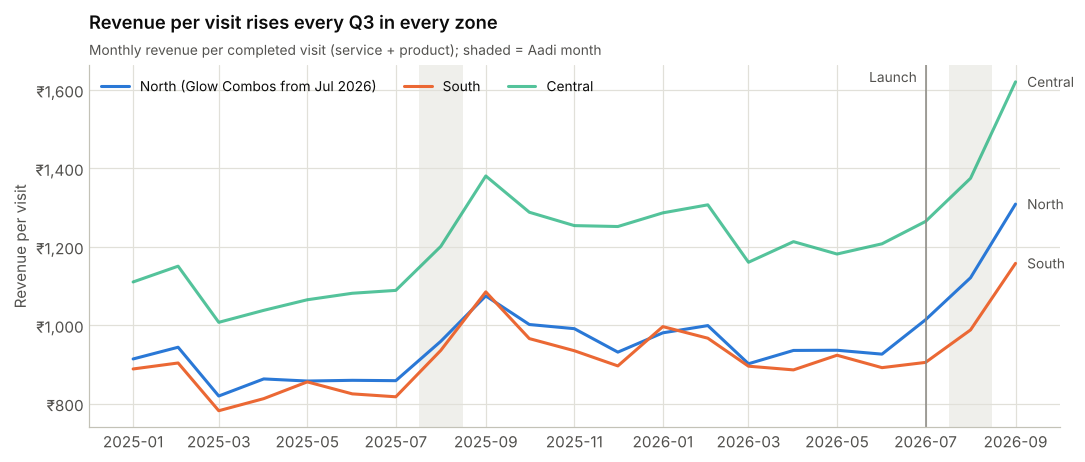

In [20]:
naive = did.naive_comparison(V)
display(naive.style.format({"Q2 2026": "Rs {:,.0f}", "Q3 2026": "Rs {:,.0f}", "change": "{:+.1%}", "visits_change": "{:+.1%}"}))
m = V.assign(month=V["date"].dt.to_period("M").dt.to_timestamp()).query("month <= '2026-09-01'") \
    .groupby(["zone", "month"]).agg(rev=("revenue", "sum"), n=("appointment_id", "size")).reset_index()
m["rpv"] = m["rev"] / m["n"]
fig = viz.zone_rpv_monthly(m, did.LAUNCH); viz.save(fig, "11_rpv_by_zone"); plt.show()
R["did_naive"] = {z: {"q2": f(naive.loc[z, "Q2 2026"]), "q3": f(naive.loc[z, "Q3 2026"]), "change": f(naive.loc[z, "change"]),
                      "visits_change": f(naive.loc[z, "visits_change"])} for z in naive.index}

Management compared North's Q3 with its Q2 and saw revenue per visit up by over 20%. But revenue per visit
rose in every zone. Q3 holds the Aavani wedding season, Onam and early festive demand (and the July dip of
Aadi), so a Q3-versus-Q2 comparison picks up the season, not the menu.

### 4.2 Choosing the control zone: testing parallel pre-trends

control,outlets,pre-trend slope (per yr),slope CI low,slope CI high,slope p (wild bootstrap),joint quarterly-leads p
South,15,-0.3%,-4.5%,+4.0%,0.868,0.745
Central,15,-5.3%,-8.6%,-1.8%,0.006,0.158


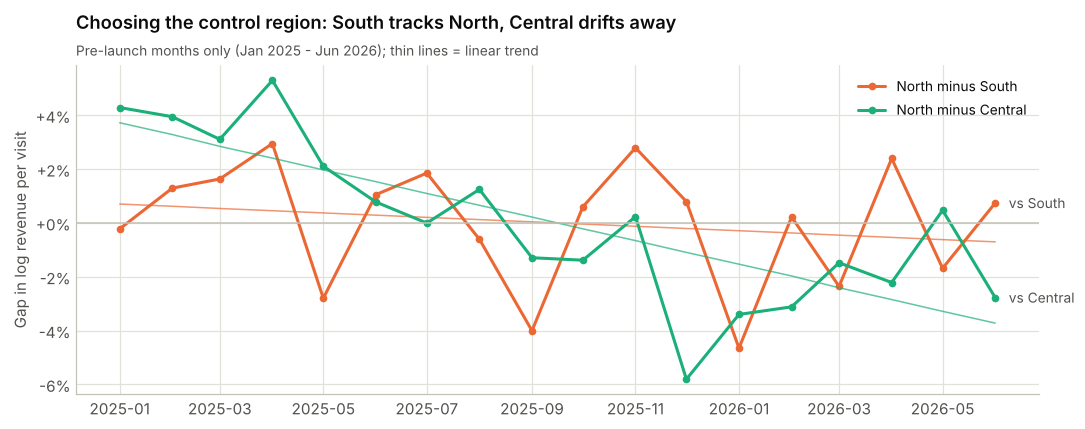

In [21]:
PW = {z: did.outlet_panel(V, zones=("North", z)) for z in ["South", "Central"]}
checks = []
for z, p in PW.items():
    lt = did.linear_pretrend(p, "log_rpv", B=9999)
    lq = did.quarterly_leads_test(p, "log_rpv")
    checks.append({"control": z, "outlets": int(p.outlet_id.nunique()), "pre-trend slope (per yr)": lt["slope_per_year"],
                   "slope CI low": lt["ci_low"], "slope CI high": lt["ci_high"], "slope p (wild bootstrap)": lt["p_value"],
                   "joint quarterly-leads p": lq["p_value"]})
checks = pd.DataFrame(checks)
display(checks.style.format({"pre-trend slope (per yr)": "{:+.1%}", "slope CI low": "{:+.1%}", "slope CI high": "{:+.1%}",
                             "slope p (wild bootstrap)": "{:.3f}", "joint quarterly-leads p": "{:.3f}"}).hide(axis="index"))
mm = V.assign(month=V["date"].dt.to_period("M").dt.to_timestamp()).query("month < '2026-07-01'").groupby(["zone", "month"]) \
    .agg(rev=("revenue", "sum"), n=("appointment_id", "size"))
lr = np.log(mm["rev"] / mm["n"]).unstack(0)
gaps = pd.concat([pd.DataFrame({"month": lr.index, "gap": lr["North"] - lr[z], "control": z}) for z in ["South", "Central"]])
gaps["gap"] = gaps.groupby("control")["gap"].transform(lambda s: s - s.mean())
fig = viz.control_choice(gaps); viz.save(fig, "12_control_choice"); plt.show()
R["did_control"] = checks.round(5).to_dict(orient="records")

**South** tracks North before the launch: its pre-trend slope is close to zero and the joint test of
pre-launch quarterly differences passes. **Central fails**: its revenue per visit drifts upward relative to
North by about 5% a year (premiumisation in RS Puram and Race Course), so using it would wrongly *shrink*
the estimated effect. **South is the control.**

### 4.3 Main estimates

Model: `log(y) = outlet FE + week FE + β·(North × post)`, on 15 outlets × 89 weeks (launch week dropped).
Week fixed effects absorb anything that hits every outlet in the same week: Aadi, the wedding seasons,
festivals, price revisions. With only 15 clusters, the confidence intervals come from a **wild cluster
bootstrap** (9,999 Rademacher draws), not just cluster-robust standard errors.

outcome,coef,cr1_ci_low,cr1_ci_high,cr1_p,wb_ci_low,wb_ci_high,wb_p,effect_%,effect_%_low,effect_%_high
Revenue per visit (log),+0.0911,+0.0590,+0.1232,0.0000,+0.0594,+0.1236,0.0002,+9.5%,+6.1%,+13.2%
Revenue per visit (Rs),+101.1127,+62.4450,+139.7804,0.0001,+61.4186,+141.1894,0.0002,,,
Visits (log),-0.0733,-0.1144,-0.0321,0.0019,-0.1164,-0.0290,0.0011,-7.1%,-11.0%,-2.9%
Total revenue (log),+0.0178,-0.0297,+0.0654,0.4341,-0.0346,+0.0718,0.4322,+1.8%,-3.4%,+7.4%


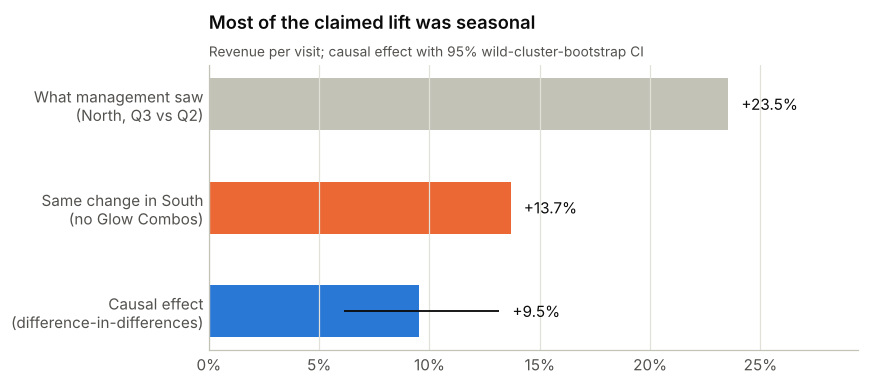

In [22]:
P = PW["South"]
main = []
for y, lab in [("log_rpv", "Revenue per visit (log)"), ("rpv", "Revenue per visit (Rs)"), ("log_visits", "Visits (log)"), ("log_revenue", "Total revenue (log)")]:
    fit = did.twfe(P, y); wb = did.wild_cluster_bootstrap(fit, "D", B=9999)
    row = {"outcome": lab, "coef": fit["D"]["coef"], "cr1_ci_low": fit["D"]["ci_low"], "cr1_ci_high": fit["D"]["ci_high"], "cr1_p": fit["D"]["p_value"],
           "wb_ci_low": wb["ci_low"], "wb_ci_high": wb["ci_high"], "wb_p": wb["p_value"]}
    if y.startswith("log"):
        row.update({"effect_%": math.exp(row["coef"]) - 1, "effect_%_low": math.exp(wb["ci_low"]) - 1, "effect_%_high": math.exp(wb["ci_high"]) - 1})
    main.append(row)
main = pd.DataFrame(main)
display(main.style.format({c: "{:+.4f}" for c in ["coef", "cr1_ci_low", "cr1_ci_high", "wb_ci_low", "wb_ci_high"]} |
                          {"cr1_p": "{:.4f}", "wb_p": "{:.4f}", "effect_%": "{:+.1%}", "effect_%_low": "{:+.1%}", "effect_%_high": "{:+.1%}"}, na_rep="").hide(axis="index"))
main.to_csv(TABLES / "did_main.csv", index=False)
mr = main.set_index("outcome")
d_rpv = mr.loc["Revenue per visit (log)"]
fig = viz.claim_vs_causal(naive.loc["North", "change"], naive.loc["South", "change"], d_rpv["effect_%"], d_rpv["effect_%_low"], d_rpv["effect_%_high"])
viz.save(fig, "13_claim_vs_causal"); plt.show()
R["did_main"] = {k: {kk: f(vv) for kk, vv in v.items()} for k, v in mr.to_dict(orient="index").items()}

- **Revenue per visit:** Glow Combos raised it by about **9.5%, roughly ₹100 a visit**, with an interval well
  clear of zero. That is real, but well under half of the +23% management saw. The rest was season and trend,
  which South, with no combos, also enjoyed.
- **Visits:** fell by about **7%** in North relative to South.
- **Total revenue:** the net effect is small and its interval includes zero.

### 4.4 Assumption checks: event study and placebos

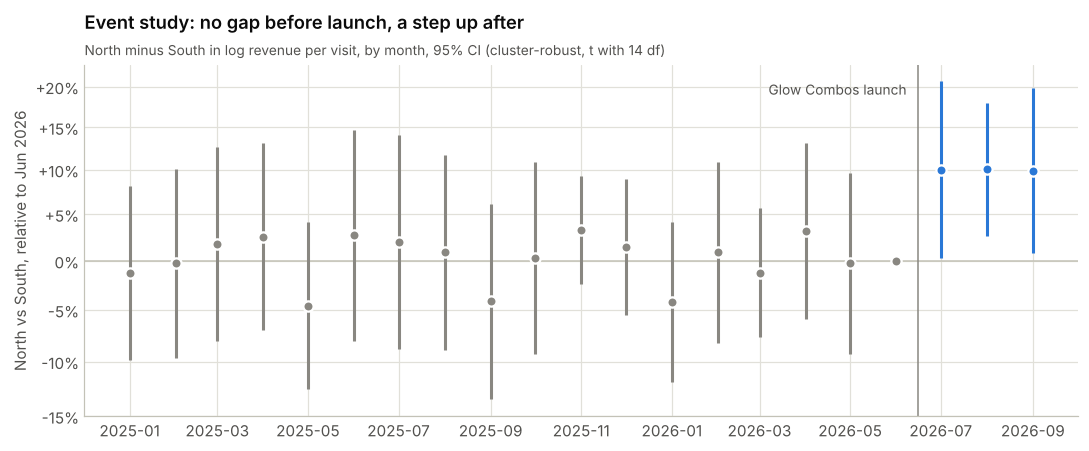

Pre-launch months: largest |gap| 0.047, none significant at 5%: True


test,estimate,ci_low,ci_high,p
"Placebo in time: fake launch 7 Jul 2025 (same season, one year earlier)",-0.0087,-0.0549,+0.0376,0.6773
Placebo in time: fake launch 5 Jan 2026 (pre-launch data only),-0.0062,-0.0320,+0.0193,0.6220
"Randomisation inference: rank of real assignment among 6,435",+0.0911,,,0.0003


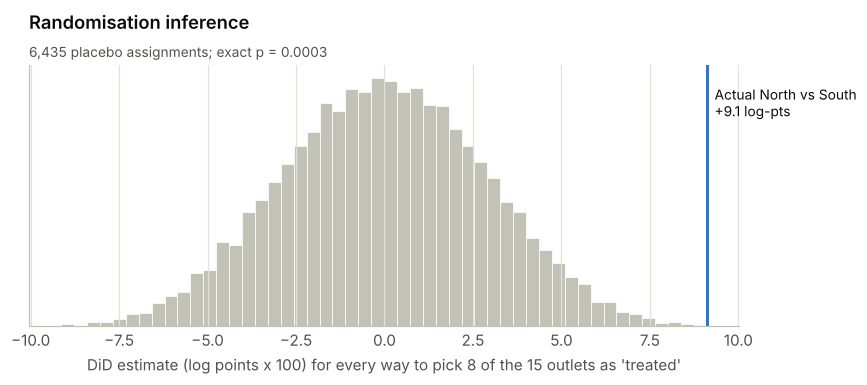

In [23]:
PM = did.outlet_panel(V, freq="month", start=pd.Timestamp("2025-01-01"), end=pd.Timestamp("2026-09-01"))
es = did.event_study(PM, "log_rpv")
fig = viz.event_study_chart(es, "Event study: no gap before launch, a step up after",
                            "North minus South in log revenue per visit, by month, 95% CI (cluster-robust, t with 14 df)")
viz.save(fig, "14_event_study"); plt.show()
pre = es[~es.post & (es.month != pd.Timestamp("2026-06-01"))]
print(f"Pre-launch months: largest |gap| {pre.coef.abs().max():.3f}, none significant at 5%: {(pre.p_value > 0.05).all()}")
pl25 = did.placebo_in_time(V, "log_rpv", "2025-01-06", "2025-07-07", "2025-09-22")
pl26 = did.placebo_in_time(V, "log_rpv", "2025-01-06", "2026-01-05", "2026-06-22")
ri = did.randomization_inference(P, "log_rpv")
plac = pd.DataFrame([{"test": "Placebo in time: fake launch 7 Jul 2025 (same season, one year earlier)", "estimate": pl25["coef"], "ci_low": pl25["ci_low"], "ci_high": pl25["ci_high"], "p": pl25["p_value"]},
                     {"test": "Placebo in time: fake launch 5 Jan 2026 (pre-launch data only)", "estimate": pl26["coef"], "ci_low": pl26["ci_low"], "ci_high": pl26["ci_high"], "p": pl26["p_value"]},
                     {"test": f"Randomisation inference: rank of real assignment among {ri['permutations']:,}", "estimate": ri["observed"], "ci_low": np.nan, "ci_high": np.nan, "p": ri["p_value"]}])
display(plac.style.format({"estimate": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "p": "{:.4f}"}, na_rep="").hide(axis="index"))
fig = viz.ri_hist(ri["perms"], ri["observed"], ri["p_value"]); viz.save(fig, "15_randomization_inference"); plt.show()
R["did_checks"] = {"event_study": es.assign(month=es.month.dt.strftime("%Y-%m")).round(5).to_dict(orient="records"),
                   "pre_max_abs": f(pre.coef.abs().max()), "pre_all_ns": bool((pre.p_value > 0.05).all()),
                   "placebo_2025": {k: f(v) if not isinstance(v, str) else v for k, v in pl25.items()},
                   "placebo_2026": {k: f(v) if not isinstance(v, str) else v for k, v in pl26.items()},
                   "ri_p": f(ri["p_value"]), "ri_rank": ri["rank"], "ri_n": ri["permutations"]}

- **Event study:** every pre-launch month sits on zero, then the gap steps up in July and stays there.
- **Placebo dates:** both fake launch dates show nothing. Notably, a fake launch one year earlier, in the same
  season, finds no North-specific Q3 bump. That rules out the worry that North simply has a stronger Q3.
- **Randomisation inference:** of the 6,435 ways to label 8 of the 15 outlets as "treated", the real
  labelling gives the most extreme estimate.

### 4.5 Robustness

In [24]:
rob = []
def rrow(name, p, y="log_rpv"):
    fit = did.twfe(p, y); wb = did.wild_cluster_bootstrap(fit, "D", B=4999)
    rob.append({"specification": name, "effect_%": math.exp(fit["D"]["coef"]) - 1, "ci_low": math.exp(wb["ci_low"]) - 1, "ci_high": math.exp(wb["ci_high"]) - 1, "p": wb["p_value"]})
rrow("Main: weekly, all visits, South control", P)
rrow("Monthly panel", PM)
rrow("Excluding occasion & bridal visits (heavy tail)", did.outlet_panel(V[V.segment != "Occasion & bridal"]))
rrow("Service revenue only (no retail)", did.outlet_panel(V.assign(revenue=V.service_revenue)))
rrow("Wrong control: Central (fails pre-trend test)", PW["Central"])
# composition: hold each outlet's pre-launch segment mix fixed
seg_list = ["Men's grooming", "Hair (women)", "Skin & beauty", "Spa"]
sp = V[V.zone.isin(["North", "South"]) & V.segment.isin(seg_list)].assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp()) \
    .query("month <= '2026-09-01'").groupby(["outlet_id", "zone", "month", "segment"]).agg(rev=("revenue", "sum"), n=("appointment_id", "size")).reset_index()
sp["rpv"] = sp.rev / sp.n
w = sp[sp.month < "2026-07-01"].groupby(["outlet_id", "segment"]).n.sum()
w = (w / w.groupby(level=0).transform("sum")).rename("w").reset_index()
mix = sp.merge(w, on=["outlet_id", "segment"]).assign(x=lambda d: d.rpv * d.w).groupby(["outlet_id", "zone", "month"]).x.sum().reset_index()
mix = mix.rename(columns={"month": "period"}).assign(log_rpv=lambda d: np.log(d.x), treated=lambda d: (d.zone == "North").astype(int),
                                                       post=lambda d: (d.period >= "2026-07-01").astype(int))
mix["D"] = mix.treated * mix.post
rrow("Fixed pre-launch service mix (removes composition effect)", mix)
rob = pd.DataFrame(rob)
display(rob.style.format({"effect_%": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}", "p": "{:.4f}"}).hide(axis="index"))
rob.to_csv(TABLES / "did_robustness.csv", index=False)
R["did_robust"] = rob.round(5).to_dict(orient="records")

specification,effect_%,ci_low,ci_high,p
"Main: weekly, all visits, South control",+9.5%,+6.1%,+13.1%,0.0000
Monthly panel,+9.8%,+6.3%,+13.5%,0.0000
Excluding occasion & bridal visits (heavy tail),+9.1%,+5.8%,+12.4%,0.0000
Service revenue only (no retail),+10.4%,+7.3%,+13.6%,0.0000
Wrong control: Central (fails pre-trend test),+2.2%,-1.7%,+6.4%,0.2589
Fixed pre-launch service mix (removes composition effect),+7.2%,+4.3%,+10.2%,0.0002


- **Robust:** the result holds across panel frequency, dropping bridal outliers, and service-only revenue.
- **Wrong control:** using Central, which fails the pre-trend test, would understate the effect.
- **Composition:** holding each outlet's service mix fixed lowers the estimate slightly. Part of the
  revenue-per-visit gain is mechanical, because low-ticket men's visits fell away, raising the average.

### 4.6 Who gained and who lost

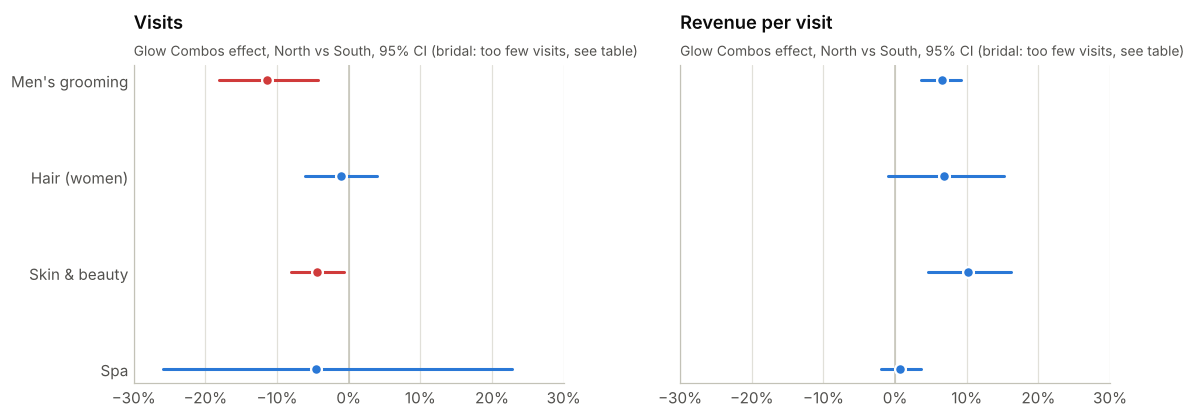

In [25]:
rows = []
for s in ["Men's grooming", "Hair (women)", "Skin & beauty", "Spa", "Occasion & bridal"]:
    ps = did.outlet_panel(V, freq="month", segment=s, start=pd.Timestamp("2025-01-01"), end=pd.Timestamp("2026-09-01"))
    for y, o in [("log_visits", "visits"), ("log_rpv", "rpv")]:
        fit = did.twfe(ps, y); wb = did.wild_cluster_bootstrap(fit, "D", B=4999)
        rows.append({"segment": s, "outcome": o, "pct": math.exp(fit["D"]["coef"]) - 1, "ci_low": math.exp(wb["ci_low"]) - 1,
                     "ci_high": math.exp(wb["ci_high"]) - 1, "p": wb["p_value"]})
dseg = pd.DataFrame(rows)
display(dseg.pivot(index="segment", columns="outcome", values=["pct", "ci_low", "ci_high", "p"]).style.format("{:+.3f}"))
fig = viz.did_segments(dseg); viz.save(fig, "16_did_segments"); plt.show()
dseg.to_csv(TABLES / "did_segments.csv", index=False)
R["did_segments"] = dseg.round(5).to_dict(orient="records")

- **Spend per visit went up where the combos are sold:** about +10% in skin & beauty (significant) and +7%
  in women's hair (not significant).
- **Lost: men's grooming.** The menu change raised the stand-alone men's haircut price by 15%. North lost
  about 11% of its men's visits relative to South, and the men who stayed paid ~6% more per visit.
- **Skin & beauty visits also slipped** about 4%. Higher spend per visit came with slightly fewer visits.
- **Spa and bridal:** too few visits to say much.

### 4.7 What it was worth in Q3

In [26]:
q3 = V[(V.zone == "North") & (V.date >= "2026-07-01") & (V.date <= "2026-09-30")]
rev_q3, vis_q3 = q3.revenue.sum(), len(q3)
b_rev = mr.loc["Total revenue (log)"]; b_vis = mr.loc["Visits (log)"]
inc = rev_q3 * (1 - math.exp(-b_rev["coef"])); inc_lo = rev_q3 * (1 - math.exp(-b_rev["wb_ci_low"])); inc_hi = rev_q3 * (1 - math.exp(-b_rev["wb_ci_high"]))
lost = vis_q3 * (math.exp(-b_vis["coef"]) - 1)
print(f"North Q3 revenue Rs {rev_q3/1e5:,.1f} lakh from {vis_q3:,} visits.")
print(f"Incremental revenue from Glow Combos: Rs {inc/1e5:+,.1f} lakh (95% CI {inc_lo/1e5:+,.1f} to {inc_hi/1e5:+,.1f}); visits lost ~ {lost:,.0f}")
R["did_value"] = {"north_q3_revenue": f(rev_q3), "north_q3_visits": int(vis_q3), "incremental": f(inc), "incremental_low": f(inc_lo),
                  "incremental_high": f(inc_hi), "visits_lost": f(lost)}

North Q3 revenue Rs 129.7 lakh from 11,252 visits.
Incremental revenue from Glow Combos: Rs +2.3 lakh (95% CI -4.6 to +9.0); visits lost ~ 855


## 5. What could make these causal estimates wrong?

**A/B test (Smart Reminders)**
1. **Broken randomisation or logging.** BB16's late integration caused an SRM. It was found by outlet-level
   checks and excluded, and the result is unchanged with it included. A bug we did *not* detect would be the
   biggest risk.
2. **Interference.** Freed slots go to other clients, some of them in control. Households share phones. Both
   blur the contrast, usually toward zero.
3. **Novelty.** Four weeks can't show whether clients start ignoring reminders. The holdout below tracks this.
4. **Measurement.** No-shows are rebuilt from timestamps and remarks (99.9% agreement with the platform log).
   Reschedules count as returns, which mechanically flatters the 45-day return metric.
5. **Ratio metrics.** Reminders create extra (rescheduled) bookings, which inflates the denominator. No-shows
   *per client* (not a ratio) also fall about 19%, so the result is not a denominator artefact.
6. **Multiple comparisons.** 20 segment estimates were tested, so some differences arise by chance. Holm
   correction and heterogeneity tests are reported.
7. **External validity.** Only opted-in, booked clients in a festive September were tested. Walk-ins and the
   rest of the year may respond differently.
8. **Concurrent change.** Glow Combos ran in North during the test. Randomisation was within outlets, so both
   arms saw it equally; the effect in North is in line with the rest.

**Difference-in-differences (Glow Combos)**
1. **Parallel trends can be tested before the launch, never after.** A North-only shock in Q3 2026 (an IT
   hiring slump, road works, a new competitor) would be attributed to combos.
2. **Spillovers.** Men priced out in North may have moved to South outlets. That inflates the control zone and
   overstates the visit loss.
3. **Composition.** Revenue per visit rises when low-ticket visits leave. That is why visits and total revenue
   are reported alongside it, and why a fixed-mix estimate is shown.
4. **Few clusters.** There are only 8 treated and 7 control outlets. Wild bootstrap and randomisation inference
   guard against over-confident standard errors.
5. **Anticipation.** If staff pushed combos before 1 July, the pre-period would be contaminated. The event
   study shows no pre-launch drift.
6. **Wrong control.** Central would have given a smaller, biased answer, so control choice matters and was
   tested, not assumed.

In [27]:
north_vs_rest = ab.segment_effects(ea.assign(nz=np.where(ea.zone == "North", "North", "South + Central")), {"nz": "Zone group"})[0]
display(north_vs_rest.style.format({"control": "{:.2%}", "treatment": "{:.2%}", "diff": "{:+.2%}", "ci_low": "{:+.2%}", "ci_high": "{:+.2%}", "p_value": "{:.3f}", "p_holm": "{:.3f}"}).hide(axis="index"))
share = e[e.zone.isin(["North", "South"])].groupby("zone").treat.mean()
print("Treatment share among enrolled clients by zone (so the A/B test cannot bias the DiD):", share.round(3).to_dict())
R["threats"] = {"ab_north": f(north_vs_rest.set_index("segment").loc["North", "diff"]),
                "ab_rest": f(north_vs_rest.set_index("segment").loc["South + Central", "diff"]),
                "treat_share_by_zone": {k: f(v) for k, v in share.items()}}

dimension,segment,clients,control,treatment,diff,ci_low,ci_high,p_value,p_holm
Zone group,North,1962,12.95%,10.64%,-2.31%,-4.88%,+0.26%,0.078,0.078
Zone group,South + Central,4020,12.10%,9.47%,-2.62%,-4.37%,-0.87%,0.003,0.007


Treatment share among enrolled clients by zone (so the A/B test cannot bias the DiD): {'North': 0.503, 'South': 0.498}


## 6. Recommendation

In [28]:
# Rough annual value of Smart Reminders (illustrative assumptions are labelled)
last12 = elig[(elig.date > A.date.max() - pd.Timedelta(days=365))]
yearly_bookings = len(last12)
prevented = yearly_bookings * -R["primary"]["diff"]
ticket = R["effects"]["Revenue per completed visit"]["treatment"]
MSG_COST, MSGS_PER_BOOKING = 0.50, 1.3                     # assumption: Rs per WhatsApp utility message, messages per booking
cost = yearly_bookings * MSGS_PER_BOOKING * MSG_COST
print(f"Eligible bookings in the last 12 months: {yearly_bookings:,}")
print(f"No-shows prevented per year at the measured effect: {prevented:,.0f} (~{prevented/365:.1f} a day across 22 outlets)")
print(f"Chair time freed, valued at the average ticket of Rs {ticket:,.0f}: Rs {prevented*ticket/1e5:,.1f} lakh a year (upper bound - only realised if freed slots are refilled)")
print(f"Messaging cost (assumed Rs {MSG_COST:.2f} x {MSGS_PER_BOOKING} messages per booking): Rs {cost/1e5:,.2f} lakh a year")
R["value_ab"] = {"yearly_eligible_bookings": int(yearly_bookings), "prevented_per_year": f(prevented), "per_day": f(prevented / 365),
                 "ticket": f(ticket), "chair_time_value": f(prevented * ticket), "msg_cost": f(cost),
                 "msg_cost_assumption": MSG_COST, "msgs_per_booking": MSGS_PER_BOOKING}

Eligible bookings in the last 12 months: 91,169
No-shows prevented per year at the measured effect: 2,298 (~6.3 a day across 22 outlets)
Chair time freed, valued at the average ticket of Rs 1,524: Rs 35.0 lakh a year (upper bound - only realised if freed slots are refilled)
Messaging cost (assumed Rs 0.50 x 1.3 messages per booking): Rs 0.59 lakh a year


In [29]:
p, dm = R["primary"], R["did_main"]
lines = [
 f"**Smart Reminders: {R['ab_decision']['decision']}.** No-show rate {p['control']:.1%} -> {p['treatment']:.1%} "
 f"({p['diff']*100:+.1f} pp, 95% CI {p['ci_low']*100:+.1f} to {p['ci_high']*100:+.1f}; {p['rel']:+.0%}). "
 f"No chain-level guardrail breached; clients aged 55+ breach the opt-out guardrail and should get a call/SMS reminder instead. "
 f"Keep a 10% holdout for 90 days to measure retention; fix BB16's integration before rollout.",
 f"**Glow Combos: EXTEND, do not scale yet.** The claimed {R['did_naive']['North']['change']:+.0%} jump in revenue per visit is mostly seasonal; "
 f"the causal effect is {dm['Revenue per visit (log)']['effect_%']:+.1%} (95% CI {dm['Revenue per visit (log)']['effect_%_low']:+.1%} to "
 f"{dm['Revenue per visit (log)']['effect_%_high']:+.1%}), but visits fell {dm['Visits (log)']['effect_%']:+.1%} - mostly men - so total revenue moved "
 f"{dm['Total revenue (log)']['effect_%']:+.1%} (95% CI {dm['Total revenue (log)']['effect_%_low']:+.1%} to {dm['Total revenue (log)']['effect_%_high']:+.1%}). "
 f"Reverse the 15% men's haircut increase, then roll out to South in a staggered (randomised-timing) design for 8 weeks before going chain-wide.",
]
display(Markdown("\n\n".join(lines)))
R["meta"] = {"generated": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "seed": 404}
def clean(o):                                     # strict JSON: numpy -> python, NaN -> null
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (bool, np.bool_)): return bool(o)
    if isinstance(o, (int, np.integer)): return int(o)
    if isinstance(o, (float, np.floating)): return None if np.isnan(o) else float(o)
    return o
with open(ROOT / "reports" / "results.json", "w") as fh:
    json.dump(clean(R), fh, indent=2, allow_nan=False, default=str)
print("Saved reports/results.json and", len(list((ROOT / "reports" / "figures").glob("*.png"))), "figures")

**Smart Reminders: GO.** No-show rate 12.4% -> 9.8% (-2.5 pp, 95% CI -4.0 to -1.1; -20%). No chain-level guardrail breached; clients aged 55+ breach the opt-out guardrail and should get a call/SMS reminder instead. Keep a 10% holdout for 90 days to measure retention; fix BB16's integration before rollout.

**Glow Combos: EXTEND, do not scale yet.** The claimed +24% jump in revenue per visit is mostly seasonal; the causal effect is +9.5% (95% CI +6.1% to +13.2%), but visits fell -7.1% - mostly men - so total revenue moved +1.8% (95% CI -3.4% to +7.4%). Reverse the 15% men's haircut increase, then roll out to South in a staggered (randomised-timing) design for 8 weeks before going chain-wide.

Saved reports/results.json and 16 figures
